# **Preparación del dataset**

## **Librerias**

In [ ]:
!pip install torchinfo -q

In [ ]:
# Importar librerías
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import random
from PIL import Image
import cv2
import glob
from tqdm.auto import tqdm # Loading bar
import os
import zipfile
plt.style.use('ggplot') # Estilo ggplot

import os
import shutil

# Importar paquetes para evaluación
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Importar paquetes de pytorch
import torch
import torch.nn as nn
from torch.autograd import Variable
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F

# Importar paquetes de  torchvision packages
import torchvision
from torchinfo import summary
from torchvision import datasets
from torchvision import transforms
# Importar librerías
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import random
from PIL import Image
import cv2
import glob
from tqdm.auto import tqdm # Loading bar
import os
import zipfile
plt.style.use('ggplot') # Estilo ggplot

import os
import shutil

# Importar paquetes para evaluación
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Importar paquetes de pytorch
import torch
import torch.nn as nn
from torch.autograd import Variable
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F

# Importar paquetes de  torchvision packages
import torchvision
from torchinfo import summary
from torchvision import datasets
from torchvision import transforms

from torch.utils.data import DataLoader, ConcatDataset, random_split

## **Carga de datos**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
local_zip = 'archive.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/content/archive')
zip_ref.close()

data_path = Path("/content/archive/")
image_path_train = data_path/"train"
image_path_test = data_path/"test"

In [ ]:
print("-----> Train data <-----")
sum_size1=0
for dirpath, dirnames, filenames in os.walk(image_path_train):
    print(f"Hay {len(filenames)} imágenes en '{dirpath}'.")
    sum_size1 = sum_size1 + len(filenames)
print("Total train  data:", sum_size1)

print("-----> Test data <-----")
sum_size2=0
for dirpath, dirnames, filenames in os.walk(image_path_test):
    print(f"Hay {len(filenames)} imágenes en '{dirpath}'.")
    sum_size2 = sum_size2 + len(filenames)
print("Total test  data:", sum_size2)

-----> Train data <-----
Hay 0 imágenes en '/content/archive/train'.
Hay 4965 imágenes en '/content/archive/train/neutral'.
Hay 4830 imágenes en '/content/archive/train/sad'.
Hay 3995 imágenes en '/content/archive/train/angry'.
Hay 436 imágenes en '/content/archive/train/disgust'.
Hay 7215 imágenes en '/content/archive/train/happy'.
Hay 3171 imágenes en '/content/archive/train/surprise'.
Hay 4097 imágenes en '/content/archive/train/fear'.
Total train  data: 28709
-----> Test data <-----
Hay 0 imágenes en '/content/archive/test'.
Hay 1233 imágenes en '/content/archive/test/neutral'.
Hay 1247 imágenes en '/content/archive/test/sad'.
Hay 958 imágenes en '/content/archive/test/angry'.
Hay 111 imágenes en '/content/archive/test/disgust'.
Hay 1774 imágenes en '/content/archive/test/happy'.
Hay 831 imágenes en '/content/archive/test/surprise'.
Hay 1024 imágenes en '/content/archive/test/fear'.
Total test  data: 7178


In [ ]:
data_path = Path("/content/archive/")
train_dir_orig = data_path/"train"
test_dir_orig = data_path/"test"

### **Juntar y Dividir Dataset**

In [ ]:
ds_part1 = datasets.ImageFolder(train_dir_orig, transform=None)
ds_part2 = datasets.ImageFolder(test_dir_orig, transform=None)

full_dataset = ConcatDataset([ds_part1, ds_part2])
total_len = len(full_dataset)

test_size = int(0.20 * total_len)
rest_size = total_len - test_size

val_size = int(0.10 * rest_size)
train_size = rest_size - val_size
train_size = train_size + (rest_size - (train_size + val_size))

# Split A
rest_set, test_set_raw = random_split(
    full_dataset, [rest_size, test_size], generator=torch.Generator().manual_seed(42)
)
# Split B
train_set_raw, val_set_raw = random_split(
    rest_set, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

print(f"Train: {len(train_set_raw)}, Val: {len(val_set_raw)}, Test: {len(test_set_raw)}")

Train: 25839, Val: 2871, Test: 7177


In [ ]:
class_names = ds_part1.classes
classes = ds_part1.class_to_idx
classes

{'angry': 0,
 'disgust': 1,
 'fear': 2,
 'happy': 3,
 'neutral': 4,
 'sad': 5,
 'surprise': 6}

## **Definir Transformaciones**

**Aplicar técnica de data augmentation y balanceo paara clases**

In [ ]:
data_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), # Asegurar 1 canal
    transforms.Resize((48, 48)),
    transforms.RandomCrop(48, padding=4),# Tamaño estándar
    transforms.RandomHorizontalFlip(p=0.5),      # Espejo (muy útil en caras)
    transforms.RandomRotation(15),               # Rotación leve (+/- 15 grados)
    transforms.ColorJitter(brightness=0.1, contrast=0.1), # Variar luz levemente
    transforms.ToTensor(),                       # Convertir a Tensor
    transforms.Normalize((0.5,), (0.5,))         # Normalizar
])

In [ ]:
val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.RandomCrop(48, padding=4),# Tamaño estándar
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [ ]:
test_transform = val_transform # Test es igual a validación

## **Aplicación de transformaciones**

Información de las imágenes
-----------------------------------------------------------
Tamaño de la imagen original (redimensionada): (48, 48)
Rango[min:7, max: 255]
-----------------------------------------------------------
Tamaño del tensor transformado: torch.Size([1, 48, 48])
Rango[min: -0.9451, max: 0.8196]




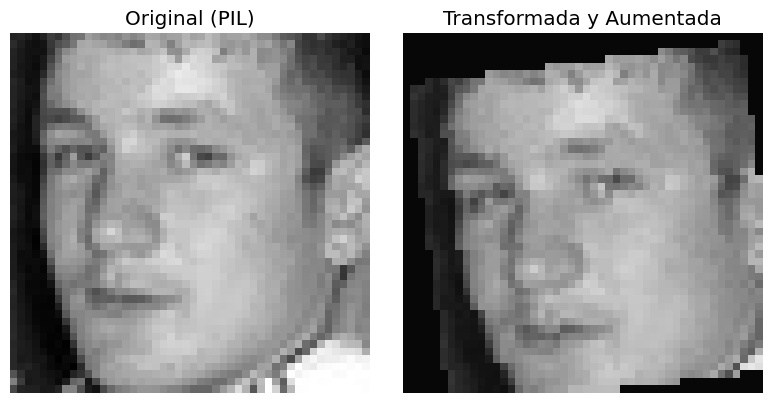

In [ ]:
image_path_list = []
for clase in classes:
    ruta_clase = os.path.join(train_dir_orig, clase)
    for archivo in os.listdir(ruta_clase):
        if archivo.endswith(('.jpg', '.png')): # Filtrar archivos de imagen
            image_path_list.append(os.path.join(ruta_clase, archivo))


random_image_path = random.choice(image_path_list)
img = Image.open(random_image_path)

# Transformación de la imagen
# Aplicamos la transformación y luego des-normalizamos para VISUALIZACIÓN
transformed_tensor = data_transform(img)

transformed_image = transformed_tensor.permute(1, 2, 0) * 0.5 + 0.5


## Información de las imágenes
print("Información de las imágenes")
# La imagen original es PIL, convertimos a numpy array para obtener min/max/shape
arr_img = np.asarray(img.resize((48, 48))) # Redimensionamos la PIL para comparar el shape con el tensor
print(f"Tamaño de la imagen original (redimensionada): {arr_img.shape}")
print(f"Rango[min:{arr_img.min()}, max: {arr_img.max()}]")
print("-----------------------------------------------------------")
# Usamos el tensor sin des-normalizar para obtener el rango real que verá la CNN
print(f"Tamaño del tensor transformado: {transformed_tensor.shape}")
print(f"Rango[min: {transformed_tensor.min():.4f}, max: {transformed_tensor.max():.4f}]")
print("\n")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(arr_img, cmap='gray')
ax[0].set_title("Original (PIL)")
ax[0].axis("off")

ax[1].imshow(transformed_image.squeeze(), cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Transformada y Aumentada")
ax[1].axis("off")

plt.tight_layout()
plt.show()

# **Modelo**

## **Crear Dataloader**

In [ ]:
class ApplyTransform(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        x, y = self.subset[idx]  # x es PIL Image
        if self.transform:
            x = self.transform(x)  # ← transforma PIL a TENSOR
        return x, y

    def __len__(self):
        return len(self.subset)

In [ ]:
BATCH_SIZE = 64

# El loader de entrenamiento debe tener shuffle=True para mezclar en cada época
train_dataset_final = ApplyTransform(train_set_raw, transform=data_transform)
val_dataset_final = ApplyTransform(val_set_raw, transform=val_transform)
test_dataset_final = ApplyTransform(test_set_raw, transform=test_transform)

train_loader = DataLoader(train_dataset_final, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset_final, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset_final, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"DataLoaders listos:")
print(f" -> Bathces de entrenamiento: {len(train_loader)}")
print(f" -> Bathces de validación: {len(val_loader)}")
print(f" -> Bathces de prueba: {len(test_loader)}")

DataLoaders listos:
 -> Bathces de entrenamiento: 404
 -> Bathces de validación: 45
 -> Bathces de prueba: 113


In [ ]:
# Verificar que hay dentro del DataLoader
train_batches, labels = next(iter(train_loader))
print(train_batches.shape)
print(labels.shape)


torch.Size([64, 1, 48, 48])
torch.Size([64])


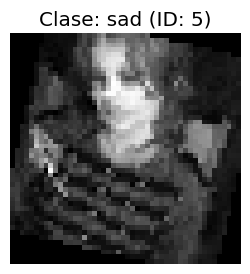

Dimensiones correctas: torch.Size([1, 48, 48])


In [ ]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Seleccionar imagen aleatoria
idx = random.randint(0, len(images)-1)
img_tensor = images[idx]
label_id = labels[idx].item()
label_name = class_names[label_id]

img_show = img_tensor.permute(1, 2, 0) * 0.5 + 0.5

plt.figure(figsize=(3,3))
plt.imshow(img_show.squeeze(), cmap='gray') # squeeze quita el canal extra si es 1
plt.title(f"Clase: {label_name} (ID: {label_id})")
plt.axis("off")
plt.show()

print(f"Dimensiones correctas: {img_tensor.shape}")

In [ ]:
# Configuración de CPU o GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

Device: cuda


## **Definir Arquitectura del Modelo**

In [ ]:
class CNNEmotion(nn.Module):
    def __init__(self, num_classes):
        super(CNNEmotion, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.dropout = nn.Dropout(0.3)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        self.dropout = nn.Dropout(0.4)

        #--> Clasificador <--
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256 * 3 * 3, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))


        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instanciar el modelo y moverlo a GPU
cnn = CNNEmotion(num_classes=len(classes)).to(device)

# Mostrar resumen del modelo
try:
    summary(cnn, input_size=(BATCH_SIZE, 1, 48, 48))
except NameError:
    print("\nResumen de la arquitectura (Instalar torchinfo para más detalles):")
    print(cnn)

In [ ]:
cnn = CNNEmotion(num_classes=len(classes)).to(device)

In [ ]:
# Probar clasificador con entrada dummy
dummy_x = torch.rand([1, 1, 48, 48]).to(device)
print(f"Tamaño del vector de entrada del clasificador: {dummy_x.size()}")

cnn.eval()
with torch.inference_mode():
    dummy_out = cnn(dummy_x)

print(f"Salida del clasificador: {dummy_out.shape}")
print(f"Salida del clasificador: {dummy_out}")

Tamaño del vector de entrada del clasificador: torch.Size([1, 1, 48, 48])
Salida del clasificador: torch.Size([1, 7])
Salida del clasificador: tensor([[-0.0067,  0.0350,  0.0127, -0.0646, -0.0271, -0.0288, -0.0093]],
       device='cuda:0')


## **Entrenamiento del Modelo**

In [ ]:
# --- CÁLCULO DE PESOS PARA BALANCEO ---

class_counts = [3995, 436, 4097, 7215, 4965, 4830, 3171]
class_counts = torch.tensor(class_counts, dtype=torch.float).to(device)
#-------
class_weights = 1.0 / (class_counts)
class_weights = torch.sqrt(class_weights + 1e-10) # <--- SUAVIZADO
class_weights = class_weights / class_weights.sum() * len(class_counts) # Normalizar
#-------

print(f"Pesos calculados para las clases: {class_weights}")
print(f"Peso para 'Disgust' (Clase 1): {class_weights[1]:.4f}")
print(f"Peso para 'Happy' (Clase 3): {class_weights[3]:.4f}")

criterion = nn.CrossEntropyLoss(weight=class_weights)

Pesos calculados para las clases: tensor([0.8058, 2.4390, 0.7957, 0.5996, 0.7228, 0.7328, 0.9044],
       device='cuda:0')
Peso para 'Disgust' (Clase 1): 2.4390
Peso para 'Happy' (Clase 3): 0.5996


Entrenamiento de Red

In [ ]:
def accuracy(y_true, y_pred):
    preds = torch.argmax(y_pred, dim=1)
    correct = (preds == y_true).sum().item()
    return correct / len(y_true)


In [ ]:
def train(dataloader: DataLoader, model: nn.Module, loss_fn, optimizer):
    model.train() # Cambiar el modelo a entrenamiento
    train_loss = 0
    train_acc = 0
    model_dtype = next(model.parameters()).dtype # Obtener el dtype de los parámetros del modelo
    for data, target in dataloader:
        # Cambiar datos a GPU. target debe ser LONG (para CrossEntropyLoss)
        data = data.to(device, dtype=model_dtype) # Mover los datos al dispositivo y asegurar que el dtype coincida
        target = target.to(device)

        train_pred_logs = model(data)

        loss = loss_fn(train_pred_logs, target)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_acc += accuracy(target, train_pred_logs)

    train_loss /= len(dataloader)
    train_acc /= len(dataloader)

    print(f"Train loss: {train_loss:.4f} | Train acc: {train_acc*100.:.4f}")
    return train_loss, train_acc

In [ ]:
def test(dataloader: DataLoader, model: nn.Module, loss_fn):
     model.eval() # Cambiar el modelo a evaluación
     test_loss = 0
     test_acc = 0
     with torch.inference_mode():
         for data, target in dataloader:
             # Cambiar datos a GPU. target debe ser LONG
             data = data.to(device)
             target = target.to(device)

             test_pred_logs = model(data)

             loss = loss_fn(test_pred_logs, target)
             test_loss += loss.item()

             # NO USAMOS torch.sigmoid. Usamos la función accuracy Multiclase
             test_acc += accuracy(target, test_pred_logs)

         test_loss /= len(dataloader)
         test_acc /= len(dataloader)

         print(f"Test loss: {test_loss:.4f} | Test acc: {test_acc*100.:.4f}")
     return test_loss, test_acc

In [ ]:
cnn = cnn.to(device)

In [ ]:
EPOCHS = 25

learning_rate = 0.001

optimizer = torch.optim.Adam(cnn.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss(weight=class_weights) # Usamos los pesos suavizados

# DEFINIR EL SCHEDULER
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=1,
    threshold=0.01,
    threshold_mode='abs'
)

loss_train = []
acc_train = []
loss_test = []
acc_test = []

for epoch in tqdm(range(EPOCHS)):
    print(f"Epoch: {epoch}\n--------" )
    train_loss, train_acc = train(train_loader, cnn, criterion, optimizer)
    test_loss, test_acc = test(val_loader, cnn, criterion)

    prev_lr = optimizer.param_groups[0]['lr']

    scheduler.step(test_loss)

    current_lr = optimizer.param_groups[0]['lr']

    if current_lr != prev_lr:
        print(f"¡ALERTA! El Scheduler bajó el LR de {prev_lr:.6f} a {current_lr:.6f}")
    # ----------------------------------------

    loss_train.append(train_loss)
    acc_train.append(train_acc)
    loss_test.append(test_loss)
    acc_test.append(test_acc)

    # Ver el LR actual al final
    print(f"LR actual: {current_lr:.6f}")

  0%|          | 0/25 [00:00<?, ?it/s]

Epoch: 0
--------
Train loss: 1.8879 | Train acc: 23.6181
Test loss: 1.7932 | Test acc: 28.5114
LR actual: 0.001000
Epoch: 1
--------
Train loss: 1.7165 | Train acc: 33.9537
Test loss: 1.5569 | Test acc: 41.0852
LR actual: 0.001000
Epoch: 2
--------
Train loss: 1.6258 | Train acc: 38.8332
Test loss: 1.5165 | Test acc: 43.6717
LR actual: 0.001000
Epoch: 3
--------
Train loss: 1.5757 | Train acc: 40.9406
Test loss: 1.4634 | Test acc: 47.3643
LR actual: 0.001000
Epoch: 4
--------
Train loss: 1.5192 | Train acc: 43.0224
Test loss: 1.3789 | Test acc: 49.2734
LR actual: 0.001000
Epoch: 5
--------
Train loss: 1.4939 | Train acc: 43.8592
Test loss: 1.3520 | Test acc: 50.5240
LR actual: 0.001000
Epoch: 6
--------
Train loss: 1.4639 | Train acc: 45.6253
Test loss: 1.3312 | Test acc: 52.2247
LR actual: 0.001000
Epoch: 7
--------
Train loss: 1.4445 | Train acc: 45.8777
Test loss: 1.3698 | Test acc: 50.5758
LR actual: 0.001000
Epoch: 8
--------
Train loss: 1.4315 | Train acc: 46.7444
Test loss: 1.2

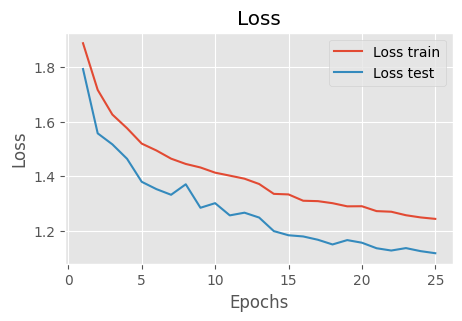

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(1,EPOCHS+1), loss_train)
plt.plot(np.arange(1,EPOCHS+1), loss_test)
plt.title('Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(['Loss train', 'Loss test'])
plt.show()

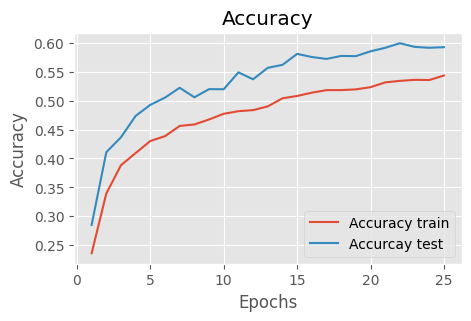

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(1,EPOCHS+1), acc_train)
plt.plot(np.arange(1,EPOCHS+1), acc_test)
plt.title('Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(['Accuracy train', 'Accurcay test'])
plt.show()

## **Evaluar el modelo**

In [ ]:
y_preds = []
y_true = []

# Poner el modelo en modo de evaluación
cnn.eval()

with torch.inference_mode():
    for X, y in tqdm(test_loader, desc="Haciendo predicciones en Test..."):
        X = X.to(device)

        y_pred_logits = cnn(X)
        y_pred_clases = torch.argmax(y_pred_logits, dim=1)
        y_preds.append(y_pred_clases.cpu())
        y_true.append(y.cpu())

# Concatenar todos los batches en un solo tensor
y_preds = torch.cat(y_preds).numpy()
y_true = torch.cat(y_true).numpy()

Haciendo predicciones en Test...:   0%|          | 0/113 [00:00<?, ?it/s]

In [ ]:
emotion_classes = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
cm = confusion_matrix(y_true, y_preds)

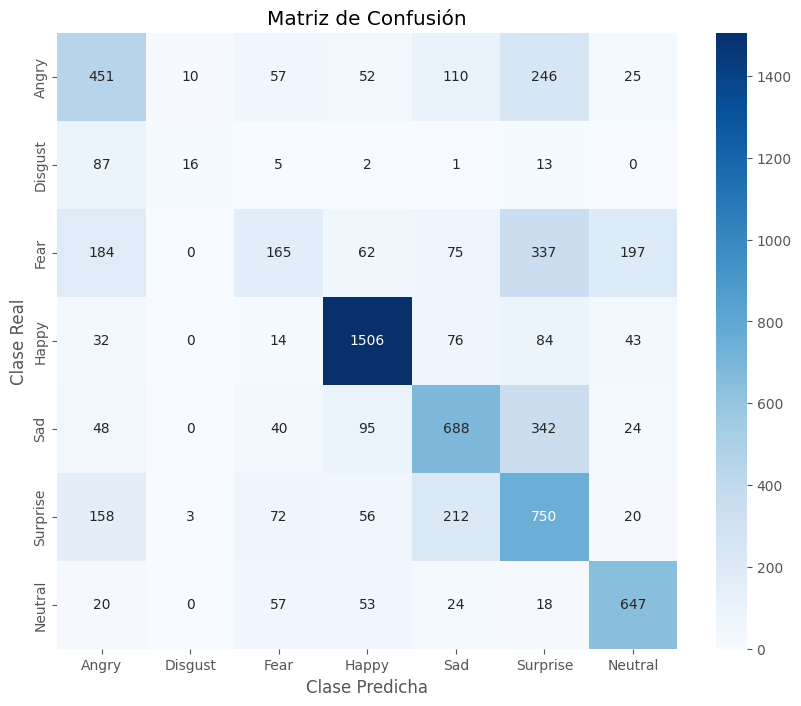

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm,
            annot=True,          # Mostrar los valores numéricos
            fmt="d",             # Formato decimal (números enteros)
            cmap="Blues",        # Color del mapa
            xticklabels=emotion_classes,
            yticklabels=emotion_classes)
plt.title("Matriz de Confusión")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show() #

In [ ]:
print("\n--- Reporte de Clasificación (Métricas Finales) ---")
print(classification_report(y_true, y_preds, target_names=emotion_classes))


--- Reporte de Clasificación (Métricas Finales) ---
              precision    recall  f1-score   support

       Angry       0.46      0.47      0.47       951
     Disgust       0.55      0.13      0.21       124
        Fear       0.40      0.16      0.23      1020
       Happy       0.82      0.86      0.84      1755
         Sad       0.58      0.56      0.57      1237
    Surprise       0.42      0.59      0.49      1271
     Neutral       0.68      0.79      0.73       819

    accuracy                           0.59      7177
   macro avg       0.56      0.51      0.51      7177
weighted avg       0.58      0.59      0.57      7177



## **Probar el Modelo con Nuevas Caras**

In [ ]:
# Seleccionar las imágenes de prueba al mismo tiempo
from google.colab import files # Re-import files
uploaded = files.upload()

Saving WhatsApp Image 2025-12-04 at 12.12.10 AM.jpeg to WhatsApp Image 2025-12-04 at 12.12.10 AM.jpeg


In [ ]:
def predict_image(model, img_tensor, device="cpu"):
    model = model.to(device)
    model.eval()

    # img_tensor debe tener forma (C, H, W)
    img_tensor = img_tensor.unsqueeze(0).to(device)  # -> (1, C, H, W)

    with torch.no_grad():
        output_logits = model(img_tensor) # Raw logits from the model

        # Convert logits to probabilities using softmax for multiclass
        probabilities = F.softmax(output_logits, dim=1)
        # Get the predicted class index (the one with the highest probability)
        predicted_class_index = torch.argmax(probabilities, dim=1)

    return probabilities, predicted_class_index

In [ ]:
def show_prediction(img_pil):
    plt.imshow(img_pil)
    plt.axis('off')
    plt.show()


Procesando imagen: WhatsApp Image 2025-12-04 at 12.12.10 AM.jpeg


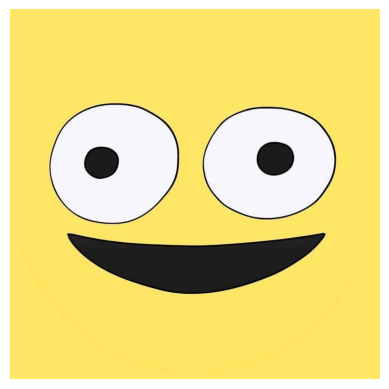

Probabilidades por clase:  tensor([[3.6222e-03, 2.2490e-06, 8.7438e-03, 8.4683e-01, 4.6183e-02, 2.0097e-03,
         9.2608e-02]])
Emoción predicha: happy (ID: 3)


In [ ]:
for filename, filedata in uploaded.items():
    print(f"\nProcesando imagen: {filename}")
    # Abrir imagen
    img_pil = Image.open(filename).convert("RGB")
    show_prediction(img_pil)
    # Transformacion para datos de prueba sin Data Augmentation
    img_tensor = test_transform(img_pil)
    # Predecir
    # y_pred will be probabilities (tensor of shape [1, 7])
    # y_class will be the predicted class index (tensor of shape [1])
    y_probabilities, y_class_index = predict_image(cnn, img_tensor, device="cpu")

    print("Probabilidades por clase: ", y_probabilities)
    predicted_emotion_id = y_class_index.item()
    predicted_emotion_name = class_names[predicted_emotion_id] # FIX: Changed from classes[predicted_emotion_id]

    print(f"Emoción predicha: {predicted_emotion_name} (ID: {predicted_emotion_id})")